# O que sustenta o ciclo: riser, lei do gás, volume a montante, gotas e a fronteira de Bøe

O fechamento do riser no blowdown, o expoente do gás, o volume de gás a montante, o arraste de gotas e a varredura da fronteira contra Bøe e Taitel.

Issues ilustradas (índice em [docs/issues/INDEX.md](../../docs/issues/INDEX.md)):
- [022](../../docs/issues/022-riser-intermitente-vs-bolhas.md)
- [023](../../docs/issues/023-lei-do-gas.md)
- [024](../../docs/issues/024-arraste-de-gotas.md)
- [026](../../docs/issues/026-volume-de-gas-a-montante.md)
- [028](../../docs/issues/028-criterio-de-boe.md)
- [029](../../docs/issues/029-fronteira-da-intermitencia-severa.md)

*Nenhuma simulação corre aqui: as corridas vêm de `notebooks/data` (dados históricos, 2026-10)
e dos lotes `batches/*.json` (`mfsim batch`); o notebook só lê e desenha.*

In [1]:
import numpy as np, matplotlib.pyplot as plt, os, json, warnings

warnings.filterwarnings("ignore")
from mfsim.fluid import Fluid
from mfsim.runs import find_run, load_run

fluid = Fluid(rhoL0=900.0, rhoG0=1.2, muL=2e-3, muG=1.8e-5, gammaL=100.0, gammaG=1.05, P0=1e5, sigma=0.05)
D = 0.05
A = np.pi * D**2 / 4
P_out = 4.0
qL = 0.3 * 900 * A
qG = 0.1 * fluid.rhoG((P_out + 1) * 1e5) * A


def datafile(fname):
    """Caminho de uma corrida gravada (notebooks/data ou runs/), ou None se não existir."""
    try:
        return find_run(fname)
    except FileNotFoundError:
        print("trajetória não encontrada:", fname)
        return None


def blowdowns(T_, P_in, min_gap=200.0):
    """Instantes dos blowdowns: mínimos locais da pressão na entrada abaixo de 30 % da
    faixa (separados por pelo menos min_gap s; um blowdown tem mínimos secundários nos
    100 s seguintes). Mais robusto do que contar picos de vazão."""
    lvl = P_in.min() + 0.3 * (P_in.max() - P_in.min())
    low = P_in < lvl
    out = []
    i = 0
    while i < T_.size:
        if low[i]:
            j = i
            while j < T_.size and low[j]:
                j += 1
            k = i + int(np.argmin(P_in[i:j]))
            if not out or T_[k] - out[-1] > min_gap:
                out.append(T_[k])
            i = j
        else:
            i += 1
    return np.array(out)


def cycle_stats(T_, P_in, q_out):
    """(número de blowdowns, período médio entre blowdowns [s], pico máximo de líquido após t = 100 s)."""
    tb = blowdowns(T_, P_in)
    per = float(np.mean(np.diff(tb))) if tb.size > 1 else np.nan
    return tb.size, per, float(q_out[T_ > 100].max())


def load_blocked_run(f):
    """Corrida gravada (partida bloqueada ou linha fechada) pelo carregador único
    `mfsim.runs.load_run` (reconstrói o caso do `meta` com os defaults deste notebook, ou de
    `case_json` nas corridas novas) e os balanços de massa; era uma cópia desta lógica."""
    r = load_run(f)
    return dict(
        meta=r.meta,
        case=r.case,
        model=r.model,
        res=r.res,
        T=r.T,
        p=r.pipe(0),
        ib=r.ib,  # célula no início do joelho
        balL=r.balance("L"),
        balG=r.balance("G"),
        acc=r.acc,  # integral BDF-consistente dos fluxos de contorno
        p_last=r.p_last,  # duto que termina no separador (rede: o último)
        aG_riser_base=r.aG_riser_base(),
    )

## Fechamento do riser, lei do gás e volume a montante (corridas com as regras físicas)

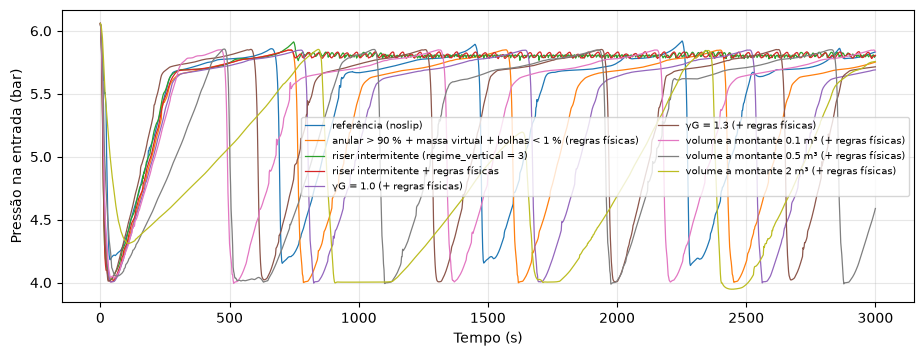

configuração                           passos    CPU blowdowns intervalo  pico máx   P_in (bar)
referência (noslip)                     25228    47 s         4     749 s    7.1 kg/s  4.14–5.92
anular > 90 % + massa virtual + bolhas < 1 % (regras físicas)    16833    39 s         4     800 s    6.1 kg/s  4.00–5.85
riser intermitente (regime_vertical = 3)   101181   293 s         1     nan s    2.0 kg/s  4.36–5.91
riser intermitente + regras físicas    112355   300 s         1     nan s    2.4 kg/s  4.31–5.85
γG = 1.0 (+ regras físicas)             17363    45 s         4     841 s    6.3 kg/s  4.00–5.85
γG = 1.3 (+ regras físicas)             17963    46 s         5     661 s    5.4 kg/s  4.01–5.85
volume a montante 0.1 m³ (+ regras físicas)    17927   157 s         4     718 s    6.4 kg/s  3.99–5.85
volume a montante 0.5 m³ (+ regras físicas)    17614   147 s         5     703 s    7.3 kg/s  3.99–5.86
volume a montante 2 m³ (+ regras físicas)    20938   170 s         4     779 s    9.3

In [2]:
runs_phys = {}
for tag, fname in (
    ("referência (noslip)", "severe_slug_blocked_conservative_arc_tol_noslip.npz"),
    (
        "anular > 90 % + massa virtual + bolhas < 1 % (regras físicas)",
        "severe_slug_blocked_conservative_arc_tol_hv_vm_lv.npz",
    ),
    ("riser intermitente (regime_vertical = 3)", "severe_slug_blocked_conservative_arc_tol_int.npz"),
    ("riser intermitente + regras físicas", "severe_slug_blocked_conservative_arc_tol_int_hv_vm_lv.npz"),
    ("γG = 1.0 (+ regras físicas)", "severe_slug_blocked_conservative_arc_tol_gammaG10.npz"),
    ("γG = 1.3 (+ regras físicas)", "severe_slug_blocked_conservative_arc_tol_gammaG13.npz"),
    ("volume a montante 0.1 m³ (+ regras físicas)", "severe_slug_blocked_conservative_arc_tol_vup01.npz"),
    ("volume a montante 0.5 m³ (+ regras físicas)", "severe_slug_blocked_conservative_arc_tol_vup05.npz"),
    ("volume a montante 2 m³ (+ regras físicas)", "severe_slug_blocked_conservative_arc_tol_vup20.npz"),
):
    f = datafile(fname)
    if f is None:
        print("trajetória não encontrada:", f)
        continue
    runs_phys[tag] = load_blocked_run(f)
if runs_phys:
    fig, ax = plt.subplots(figsize=(11, 3.8))
    for tag, r in runs_phys.items():
        ax.plot(r["T"], r["p"]["out"]["P_bar"][1], lw=0.9, label=tag)
    ax.set_ylabel("Pressão na entrada (bar)")
    ax.set_xlabel("Tempo (s)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, ncol=2)
    plt.show()
    print(
        f"{'configuração':36s} {'passos':>8s} {'CPU':>6s} {'blowdowns':>9s} {'intervalo':>9s} {'pico máx':>9s} {'P_in (bar)':>12s}"
    )
    for tag, r in runs_phys.items():
        T_, q_ = r["T"], r["p"]["out"]["qL"][-1]
        nb_, per, qmax = cycle_stats(T_, r["p"]["out"]["P_bar"][1], q_)
        P1 = r["p"]["out"]["P_bar"][1][T_ > 100]
        print(
            f"{tag:36s} {r['meta']['n_steps']:8d} {r['meta']['cpu']:5.0f} s {nb_:9d} {per:7.0f} s {qmax:6.1f} kg/s {P1.min():5.2f}–{P1.max():4.2f}"
        )

### Fronteira de Bøe e o fechamento do riser

Critério de Bøe (1981), na forma citada por Taitel (1986) e Jansen et al. (1996):
há intermitência severa se vSL ≥ vSL_mín = P_base·vSG / (ρL g (1 − αG) L), com L o
comprimento de linha ocupado pelo gás e **sem** fator de inclinação. (Correção de
2026-10-13: a versão anterior desta análise dividia L por sin|θ|, o que não consta das
fontes e dava vSL_mín = 1.03 m/s para o caso base; o valor correto é 0.06 m/s.) Com a
forma correta **todos** os pontos simulados estão dentro da região de Bøe, inclusive o
caso base (vSL = 0.30 ≫ 0.06): o ciclo com bolhas no riser é coerente com Bøe, e a
ausência de ciclo com intermitente no riser no caso base é uma sensibilidade do modelo ao
fechamento do riser, não uma previsão do critério. Acima de 1.2 m/s os dois fechamentos
dão escoamento permanente porque a linha deixa de ser estratificada (Taitel 1986 exige as
duas condições). O caso de linha longa (1000 m, 2 bar) cicla com bolhas e com intermitente:
aí os dois fechamentos dão o ciclo clássico (pressurização lenta da linha com o riser
cheio de líquido, blowdown, reenchimento), com período 3850–4280 s (±10 %) e picos de
7.8–8.9 kg/s. O caso base é um caso de fronteira, dependente do fechamento a baixa
fração de gás no riser; o de linha longa demonstra o mecanismo de forma robusta.
(O intermitente sem as regras físicas não passa da partida neste caso: blowdown
inicial violento com 0.3 bar de sobrepressão, rastejo no riser cheio de líquido com 0.1.)

In [3]:
from mfsim.analysis import boe_criterion

runs_boe = {}
for tag, fname in (
    ("caso base, bolhas no riser", "severe_slug_blocked_conservative_arc_tol_noslip.npz"),
    ("caso base, intermitente no riser", "severe_slug_blocked_conservative_arc_tol_int.npz"),
    ("vSL = 1.2, bolhas", "severe_slug_blocked_conservative_arc_tol_v12_bub.npz"),
    ("vSL = 1.2, intermitente", "severe_slug_blocked_conservative_arc_tol_v12_int.npz"),
    ("vSL = 1.6, bolhas", "severe_slug_blocked_conservative_arc_tol_v16_bub.npz"),
    ("vSL = 1.6, intermitente", "severe_slug_blocked_conservative_arc_tol_v16_int.npz"),
    ("L = 1000 m, 2 bar, bolhas", "severe_slug_blocked_conservative_arc_boe_bub.npz"),
    ("L = 1000 m, 2 bar, bolhas, sobrepressão 0.1 bar", "severe_slug_blocked_conservative_arc_boe_bub_dp01.npz"),
    ("L = 1000 m, 2 bar, bolhas + regras físicas", "severe_slug_blocked_conservative_arc_boe_bub_rules.npz"),
    ("L = 1000 m, 2 bar, intermitente + regras físicas", "severe_slug_blocked_conservative_arc_boe_int_rules.npz"),
    ("L = 1000 m, 2 bar, vSL = 0.5, regras", "severe_slug_blocked_conservative_arc_scan_P2_v05.npz"),
    ("L = 1000 m, 2 bar, vSL = 0.8, regras", "severe_slug_blocked_conservative_arc_scan_P2_v08.npz"),
    ("L = 1000 m, 4 bar, vSL = 0.5, regras", "severe_slug_blocked_conservative_arc_scan_P4_v05.npz"),
    ("L = 1000 m, 4 bar, vSL = 0.8, regras", "severe_slug_blocked_conservative_arc_scan_P4_v08.npz"),
    ("L = 1000 m, 2 bar, vSL = 0.15, regras", "severe_slug_blocked_conservative_arc_scan_P2_v015.npz"),
    ("L = 1000 m, 2 bar, vSL = 0.3, regras", "severe_slug_blocked_conservative_arc_scan_P2_v03.npz"),
    ("L = 1000 m, 4 bar, vSL = 0.3, regras", "severe_slug_blocked_conservative_arc_scan_P4_v03.npz"),
    ("L = 1000 m, 2 bar, vSG = 0.05, regras", "severe_slug_blocked_conservative_arc_scan_P2_g005.npz"),
    ("L = 1000 m, 2 bar, vSG = 0.2, regras", "severe_slug_blocked_conservative_arc_scan_P2_g02.npz"),
    ("L = 1000 m, 2 bar, 2 m³ a montante (vértice), regras", "severe_slug_blocked_conservative_arc_boe_vup20.npz"),
    ("L = 1000 m, 2 bar, vSG = 0.2, intermitente + regras", "severe_slug_blocked_conservative_arc_scan_P2_g02_int.npz"),
    ("caso base + 200 m de linha de entrada, regras", "severe_slug_blocked_conservative_arc_tol_lh1_200.npz"),
    ("caso base + 500 m de linha de entrada, regras", "severe_slug_blocked_conservative_arc_tol_lh1_500.npz"),
    ("L = 1000 m, 2 bar, γG = 1.3, regras", "severe_slug_blocked_conservative_arc_scan_P2_v03_gammaG13.npz"),
):
    f = datafile(fname)
    if f is None:
        print("trajetória não encontrada:", f)
        continue
    r_ = load_blocked_run(f)
    mb = r_["meta"]  # P_in pelo Results (o índice do estado muda com vértice a montante)
    T_ = r_["T"]
    P1 = r_["p"]["out"]["P_bar"][1]
    sel = T_ > 300
    P_base = mb.get("P_out", 4.0) * 1e5 + fluid.rhoL0 * 9.81 * mb.get("H_riser", 20.0)
    # a alimentação de gás é definida a P_out + 1 bar (severe_D.py); vSG à pressão do separador
    vSG_ = mb.get("vSG", 0.1) * fluid.rhoG((mb.get("P_out", 4.0) + 1.0) * 1e5) / fluid.rhoG(mb.get("P_out", 4.0) * 1e5)
    vmin, severe = boe_criterion(
        mb.get("vSL", 0.3), vSG_, P_base, fluid.rhoL0, 0.5, mb.get("L_h1", 20.0) + mb.get("L_down", 300.0)
    )  # L de gás = linha de entrada + descendente
    amp = P1[sel].max() - P1[sel].min()
    tb = blowdowns(T_[sel], P1[sel]) if amp > 0.3 else np.array([])  # sem oscilação de pressão não há blowdown
    per = float(np.mean(np.diff(tb))) if tb.size > 1 else np.nan
    runs_boe[tag] = dict(
        vSL=mb.get("vSL", 0.3),
        L=mb.get("L_down", 300.0),
        P=mb.get("P_out", 4.0),
        vmin=vmin,
        n_steps=mb["n_steps"],
        amp=P1[sel].max() - P1[sel].min(),
        nb=tb.size,
        per=per,
    )
if runs_boe:
    print(
        f"{'caso':34s} {'vSL':>5s} {'L (m)':>6s} {'P_out':>6s} {'vSL_mín Bøe':>12s} {'passos':>7s} {'ΔP_in (t>300 s)':>16s} {'blowdowns':>9s} {'intervalo':>9s}"
    )
    for tag, r in runs_boe.items():
        print(
            f"{tag:34s} {r['vSL']:5.2f} {r['L']:6.0f} {r['P']:6.1f} {r['vmin']:12.3f} {r['n_steps']:7d} {r['amp']:12.2f} bar {r['nb']:9d} {r['per']:7.0f} s"
        )

caso                                 vSL  L (m)  P_out  vSL_mín Bøe  passos  ΔP_in (t>300 s) blowdowns intervalo
caso base, bolhas no riser          0.30    300    4.0        0.050   25228         1.78 bar         3     790 s
caso base, intermitente no riser    0.30    300    4.0        0.050  101181         0.23 bar         0     nan s
vSL = 1.2, bolhas                   1.20    300    4.0        0.050     555         0.04 bar         0     nan s
vSL = 1.2, intermitente             1.20    300    4.0        0.050    1123         0.00 bar         0     nan s
vSL = 1.6, bolhas                   1.60    300    4.0        0.050     356         0.03 bar         0     nan s
vSL = 1.6, intermitente             1.60    300    4.0        0.050    3325         0.03 bar         0     nan s
L = 1000 m, 2 bar, bolhas           0.30   1000    2.0        0.012  105019         1.68 bar         2    3750 s
L = 1000 m, 2 bar, bolhas, sobrepressão 0.1 bar  0.30   1000    2.0        0.012   63993        

### Arraste de gotas: é relevante?

A tese não tem arraste de gotas. Antes de modelar, a fração arrastada de Ishii &
Mishima (1989), E = tanh(7.25e−7·We^1.25·Re_L^0.25), é avaliada em pós-processamento nas
células do riser das trajetórias gravadas. Só é apreciável nos poucos segundos do pico de
gás do blowdown dos casos de linha longa (vSG ≈ 28 m/s no topo); o líquido produzido
nesses instantes é 1–5 % do total. Não se justifica um campo de gotas para estes casos.

In [4]:
def ishii_E(vSL, vSG, rhoL, rhoG, muL, sigma, D_):
    We = rhoG * vSG**2 * D_ / sigma * np.cbrt(np.abs(rhoL - rhoG) / rhoG)
    ReL = rhoL * np.abs(vSL) * D_ / muL
    return np.tanh(7.25e-7 * np.maximum(We, 0) ** 1.25 * np.maximum(ReL, 1e-9) ** 0.25)


runs_ent = {}
for tag, fname in (
    ("caso base, regras físicas", "severe_slug_blocked_conservative_arc_tol_hv_vm_lv.npz"),
    ("caso base + 500 m de linha de entrada", "severe_slug_blocked_conservative_arc_tol_lh1_500.npz"),
    ("linha de 1000 m, 2 bar, bolhas + regras", "severe_slug_blocked_conservative_arc_boe_bub_rules.npz"),
    ("linha de 1000 m, 2 bar, vSG = 0.29", "severe_slug_blocked_conservative_arc_scan_P2_g02.npz"),
):
    f = datafile(fname)
    if f is None:
        print("trajetória não encontrada:", f)
        continue
    runs_ent[tag] = load_blocked_run(f)
print(
    f"{'caso':42s} {'riser > 90 % gás':>16s} {'E > 0.1':>8s} {'E máx':>6s} {'vSG máx':>8s} {'produção com E_topo > 0.1':>26s}"
)
for tag, r in runs_ent.items():
    th_ = np.rad2deg(r["model"].pipes[0].scheme.theta_nodes)
    riser_ = np.flatnonzero(th_ > 80)
    T_ = r["T"]
    aG_ = r["p"]["out"]["alphaG"][riser_]
    vSL_ = r["p"]["out"]["velocidadeSL"][riser_]
    vSG_ = r["p"]["out"]["velocidadeSG"][riser_]
    P_ = r["p"]["out"]["P_bar"][riser_] * 1e5
    E_ = ishii_E(vSL_, vSG_, fluid.rhoL0, fluid.rhoG(P_), fluid.muL, fluid.sigma, D)
    ann_ = aG_ > 0.9
    qo = r["p"]["out"]["qL"][-1]
    frac = np.trapezoid(np.where(E_[-1] > 0.1, qo, 0), T_) / np.trapezoid(qo, T_)
    print(
        f"{tag:42s} {ann_.mean():16.1%} {np.mean(E_[ann_] > 0.1) if ann_.any() else 0:8.1%} {E_.max():6.2f} {vSG_.max():6.1f} m/s {frac:26.1%}"
    )

caso                                       riser > 90 % gás  E > 0.1  E máx  vSG máx  produção com E_topo > 0.1
caso base, regras físicas                             21.4%     0.0%   0.12    9.3 m/s                       0.0%
caso base + 500 m de linha de entrada                 47.4%     0.1%   0.16   11.1 m/s                       5.0%
linha de 1000 m, 2 bar, bolhas + regras               11.2%     1.0%   0.56   28.9 m/s                       1.1%
linha de 1000 m, 2 bar, vSG = 0.29                    15.7%     0.5%   0.61   27.4 m/s                       1.5%
